In [45]:
from pathlib import Path
from sklearn.model_selection import train_test_split
import tarfile
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

TEST_SPLIT = 0.2
SEED = 42

### Downloading data

In [46]:
tar_path = Path("dataset/housing.tgz")

if not tar_path.is_file():
    dataset_path = Path("dataset")
    dataset_path.mkdir(parents=True, exist_ok=True)

    url = "https://github.com/ageron/data/raw/main/housing.tgz"
    urllib.request.urlretrieve(url, tar_path)

    with tarfile.open(tar_path) as tar:
        tar.extractall(path=dataset_path, filter="data")

df = pd.read_csv("dataset/housing/housing.csv")

### Quick look

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


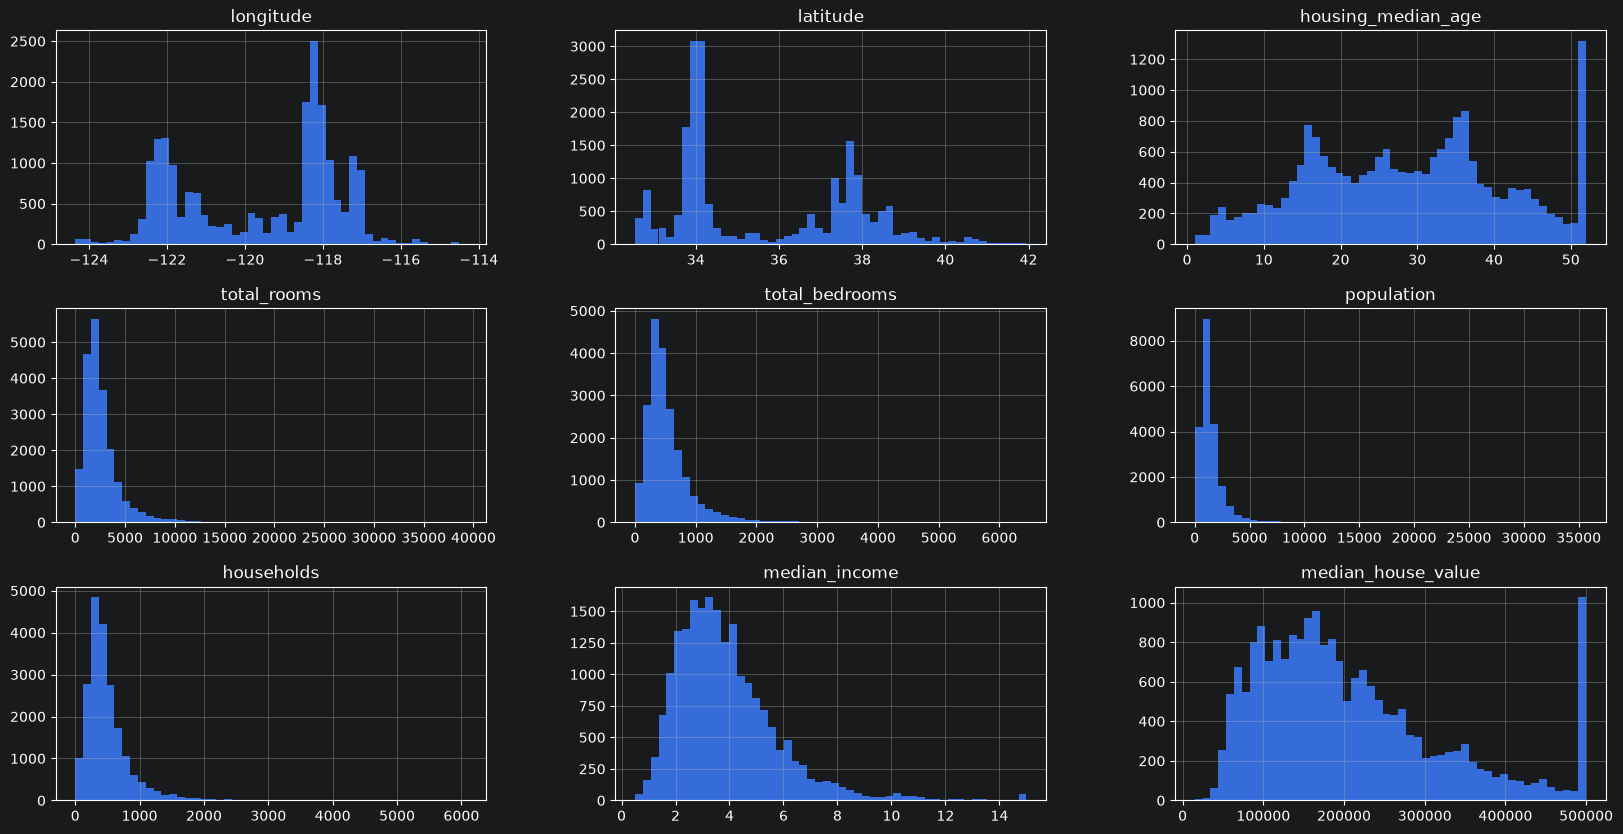

In [47]:
df.head()
df.info()
df.describe()
df.hist(bins=50, figsize=(20, 10))
plt.show()

### Create test cases

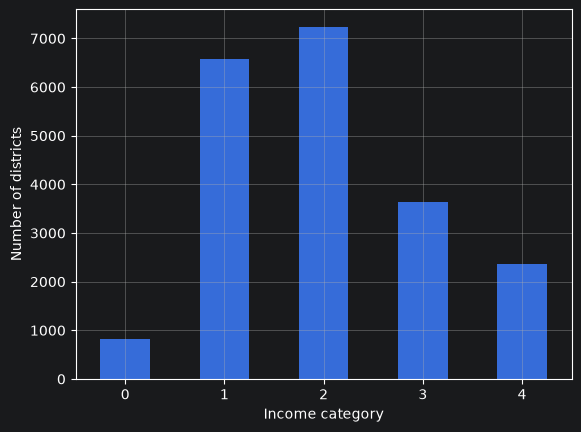

In [48]:
df["income_cat"] = pd.cut(df["median_income"],
                                    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                    labels=[0, 1, 2, 3, 4])

cat_counts = df["income_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
plt.show()

In [49]:
strat_train_set, strat_test_set = train_test_split(
    df,
    test_size=TEST_SPLIT,
    stratify=df["income_cat"],
    random_state=42
)

# can compare % error against overall and random split to see sampling bias
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
2    0.350533
1    0.318798
3    0.176357
4    0.114341
0    0.039971
Name: count, dtype: float64

In [50]:
for set_ in (strat_train_set, strat_test_set): set_.drop("income_cat", axis=1, inplace=True)

### Exploration and Visulisation

In [51]:
train_df = strat_train_set.copy()

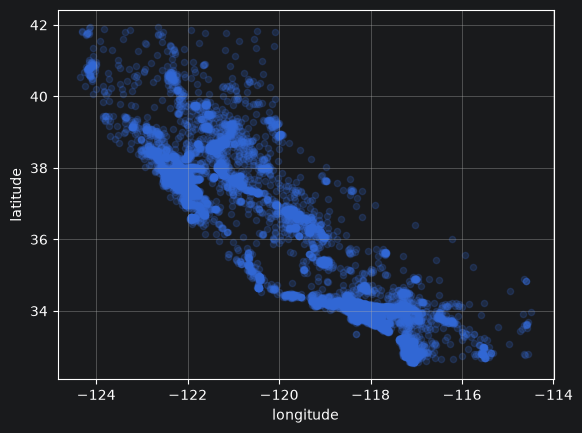

In [52]:
train_df.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)
plt.show()

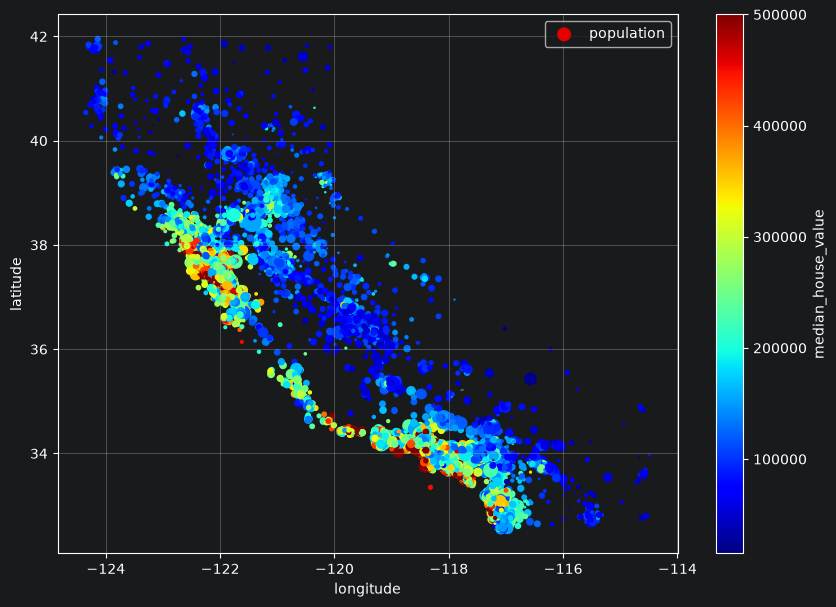

In [53]:
train_df.plot(kind="scatter",
              x="longitude",
              y="latitude",
              grid=True,
              s=train_df["population"] / 100,
              label="population",
              c="median_house_value",
              cmap="jet",
              colorbar=True,
              legend=True,
              sharex=False,
              figsize=(10, 7))
plt.show()

### Look for correlations

In [54]:
corr_matrix = train_df.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

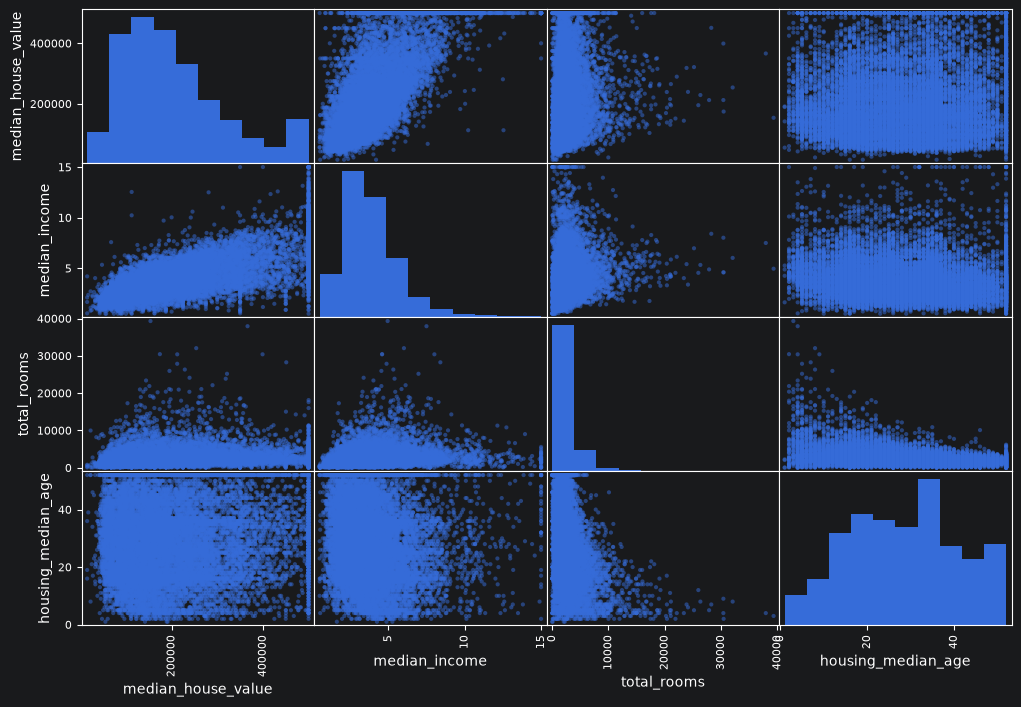

In [55]:
from pandas.plotting import scatter_matrix
attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
scatter_matrix(train_df[attributes], figsize=(12, 8))
plt.show()

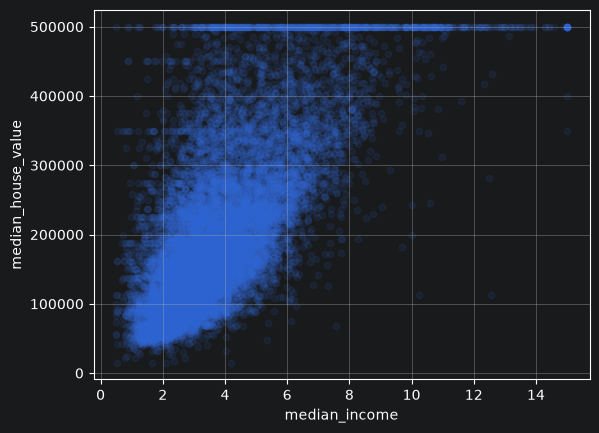

In [56]:
train_df.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.1, grid=True)
plt.show()

Analysis above highlights skewnes (which is to be considered for log or sqrroot transformation) as well as lines in plots that might need cleaning up

In [57]:
train_df["rooms_per_house"] = train_df["total_rooms"] / train_df["households"]
train_df["bedrooms_ratio"] = train_df["total_bedrooms"] / train_df["total_rooms"]
train_df["people_per_house"] = train_df["population"] / train_df["households"]

In [58]:
corr_matrix = train_df.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

This round of explanation does not have to be absolutely thorough; the point is to start off on the right foot
and quickly gain insights that will help you get a first reasonably good prototype. But this is an iterative
process: once you get a prototype up and running, you can analyze its output to gain more in sights and come
back to this exploration step.

### Prepare data for ML Algorithms

In [59]:
# isolate the training data again
train_df = strat_train_set.drop("median_house_value", axis=1)
train_df_labels = strat_train_set["median_house_value"].copy()

# impute the missing values with median value ensuring to apply to only numericals
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")

train_df_num = train_df.select_dtypes(include=[np.number])
imputer.fit(train_df_num)

imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [60]:
train_df_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [61]:
# use inputer to transform the training set
x = imputer.transform(train_df_num)

# and transfer from numpy array back to df
train_df_tr = pd.DataFrame(x, train_df_num.index, train_df_num.columns)

In [62]:
# handling text - we can see these are categories
train_df_cat = train_df[["ocean_proximity"]]
train_df_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


In [63]:
# numerical values are preferred - let's convert
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
train_df_cat_encoded = ordinal_encoder.fit_transform(train_df_cat)
train_df_cat_encoded[:8] # first 8 values

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [64]:
# we'll do one-hot encoding to ensure models do not interpret numerical values outside the categorical meaning
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
train_df_cat_1hot = cat_encoder.fit_transform(train_df_cat)

train_df_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(16512, 5))

### Feature scaling and transformation

In [65]:
# There are 2 common ways to get all attributes to have the same scale: min-max (normalization) and standardization

from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
train_df_num_min_max_scaled = min_max_scaler.fit_transform(train_df_num)

from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()
train_df_num_std_scaled = std_scaler.fit_transform(train_df_num)

# When there is a heavy tail you want to make the distribution roughly similar, you can:
# a) apply log
# b) bucketize the features

In [66]:
# easier to setup pipelines
from sklearn.pipeline import Pipeline
num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

### Pipeline tasks
- missing numerical values will be imputed by replacing with median
- missing categorical values will be replaced with most frequent category
- categorical feature will be one-hot encoded (most MLs accept only numerical input)
- a few ratio features will be computed and added: bedrooms_ratio, rooms_per_house, people_per_house. Hopefully these will better correlate with the median house value.
- a few cluster similarity features will be added. These will likely be more usefol to the model than latitude and longitude.
- long-tail features will be replaces by their logarithm, as most models prefer features with roughly uniform or Gaussian distributions
- all numerical features will be standartized, as most MLs prefer when all features have roughly the same scale